# TP 0 bis — Pour aller plus loin
### Algorithmique avancée et complexité — Master IA

> 📌 Ce notebook **complète** le TP 0. Il est prévu pour la fin de séance s'il reste du temps, ou pour travailler en autonomie.

## 🎯 Objectifs

**Partie A — Git avancé**
- travailler avec des **branches** (créer, changer, fusionner, supprimer) ;
- comprendre et **résoudre un conflit** de fusion ;
- le circuit **Pull Request** sur GitHub ;
- **annuler** proprement une erreur (`restore`, `revert`, `stash`…).

**Partie B — Python avancé**
- itérateurs, générateurs, compréhensions ;
- fonctions d'ordre supérieur, **décorateurs**, **mémoïsation** ;
- la bibliothèque standard utile en algorithmique : `collections`, `heapq`, `bisect`, `itertools`, `timeit` ;
- annotations de type, `dataclass`, exceptions, gestionnaires de contexte ;
- **NumPy** : vectoriser au lieu de boucler.

> 💡 Chaque notion est reliée à la **complexité** : c'est le fil rouge du module.

---
# Partie A — Git avancé : les branches

## A.1 Pourquoi des branches ?

Une **branche** est une ligne de développement indépendante. On peut essayer une idée **sans toucher** à la version qui marche (`main`), puis la **fusionner** si elle est bonne ou la jeter sinon.

```
main      ●───●───────────●   ← fusion (merge)
               \         /
feature         ●───●───●     ← vos essais, isolés
```

Cas d'usage typiques :
- tester une **autre version d'un algorithme** (ex. Fibonacci itératif) sans casser la version actuelle ;
- **travailler à plusieurs** : chacun sur sa branche, puis on fusionne ;
- un TP = une branche, fusionnée dans `main` quand il est terminé.

Une branche n'est qu'une **étiquette** qui pointe vers un commit : la créer est instantané et ne copie aucun fichier.

## A.2 Les commandes essentielles

| Commande | Effet |
|---|---|
| `git branch` | lister les branches (`*` = branche courante) |
| `git switch -c tp1` | **créer** la branche `tp1` et s'y placer |
| `git switch main` | revenir sur `main` |
| `git merge tp1` | fusionner `tp1` **dans la branche courante** |
| `git branch -d tp1` | supprimer `tp1` (une fois fusionnée) |
| `git log --oneline --graph --all` | voir l'arbre des commits |
| `git push -u origin tp1` | publier la branche sur GitHub |

> Les anciens tutoriels utilisent `git checkout -b tp1` : c'est équivalent à `git switch -c tp1`.

> Dans VS Code, le **nom de la branche** est affiché en bas à gauche : cliquer dessus pour en changer ou en créer une.

## A.3 Démonstration en direct

Les cellules suivantes créent un **dépôt jetable** dans un dossier temporaire et y jouent un scénario complet. Rien n'est modifié dans vos vrais projets.

La fonction `git(...)` lance une commande Git et affiche son résultat. Elle fonctionne sous Windows, macOS et Linux.

In [29]:
import subprocess, tempfile, pathlib

depot = pathlib.Path(tempfile.mkdtemp(prefix="demo_git_"))

def git(*args):
    # Lance `git <args>` dans le dépôt de démonstration et affiche la sortie.
    r = subprocess.run(["git", "-c", "user.name=Demo", "-c", "user.email=demo@exemple.dz", *args],
                       cwd=depot, capture_output=True, text=True)
    print(f"$ git {' '.join(args)}\n{r.stdout}{r.stderr}")

def ecrire(nom, texte):
    (depot / nom).write_text(texte, encoding="utf-8")

git("init", "-b", "main")
ecrire("fib.py", "def fib(n):\n    if n <= 1:\n        return n\n    return fib(n - 1) + fib(n - 2)\n")
git("add", "fib.py")
git("commit", "-m", "Fibonacci récursif naïf")

$ git init -b main
Initialized empty Git repository in /private/var/folders/15/3trdtd8x32706268pzfjmk2r0000gn/T/demo_git_febteqet/.git/

$ git add fib.py

$ git commit -m Fibonacci récursif naïf
[main (root-commit) d21e476] Fibonacci récursif naïf
 1 file changed, 4 insertions(+)
 create mode 100644 fib.py



On crée une branche `iteratif` pour essayer une version plus rapide, **sans toucher** à `main` :

In [30]:
git("switch", "-c", "iteratif")
ecrire("fib.py", "def fib(n):\n    a, b = 0, 1\n    for _ in range(n):\n        a, b = b, a + b\n    return a\n")
git("commit", "-am", "Fibonacci itératif")
git("switch", "main")
print("Contenu de fib.py sur main :\n" + (depot / "fib.py").read_text())

$ git switch -c iteratif
Switched to a new branch 'iteratif'

$ git commit -am Fibonacci itératif
[iteratif 3a82a5f] Fibonacci itératif
 1 file changed, 4 insertions(+), 3 deletions(-)

$ git switch main
Switched to branch 'main'

Contenu de fib.py sur main :
def fib(n):
    if n <= 1:
        return n
    return fib(n - 1) + fib(n - 2)



👆 Sur `main`, le fichier n'a **pas changé** : le travail est rangé dans la branche. On fusionne maintenant :

In [31]:
git("merge", "iteratif")
git("log", "--oneline", "--graph", "--all")
git("branch", "-d", "iteratif")

$ git merge iteratif
Updating d21e476..3a82a5f
Fast-forward
 fib.py | 7 ++++---
 1 file changed, 4 insertions(+), 3 deletions(-)

$ git log --oneline --graph --all
* 3a82a5f Fibonacci itératif
* d21e476 Fibonacci récursif naïf

$ git branch -d iteratif
Deleted branch iteratif (was 3a82a5f).



Ici `main` n'avait pas bougé depuis la création de la branche : Git a simplement **avancé l'étiquette** (*fast-forward*).

## A.4 Les conflits de fusion

Un **conflit** survient quand **deux branches modifient les mêmes lignes** différemment. Git ne peut pas deviner laquelle garder : il vous demande de choisir.

In [32]:
git("switch", "-c", "auteur-ali")
ecrire("README.md", "# TP Fibonacci\nAuteur : Ali\n")
git("add", "README.md"); git("commit", "-m", "README par Ali")

git("switch", "main")
ecrire("README.md", "# TP Fibonacci\nAuteur : Sara\n")
git("add", "README.md"); git("commit", "-m", "README par Sara")

git("merge", "auteur-ali")
print((depot / "README.md").read_text())

$ git switch -c auteur-ali
Switched to a new branch 'auteur-ali'

$ git add README.md

$ git commit -m README par Ali
[auteur-ali 584e02f] README par Ali
 1 file changed, 2 insertions(+)
 create mode 100644 README.md

$ git switch main
Switched to branch 'main'

$ git add README.md

$ git commit -m README par Sara
[main a7c8a2d] README par Sara
 1 file changed, 2 insertions(+)
 create mode 100644 README.md

$ git merge auteur-ali
Auto-merging README.md
CONFLICT (add/add): Merge conflict in README.md
Automatic merge failed; fix conflicts and then commit the result.

# TP Fibonacci
<<<<<<< HEAD
Auteur : Sara
Auteur : Ali
>>>>>>> auteur-ali



Git a écrit les **deux versions** dans le fichier, entre des marqueurs :

```
<<<<<<< HEAD          ← votre version (branche courante)
=======
>>>>>>> auteur-ali    ← la version qui arrive
```

**Pour résoudre** :
1. éditer le fichier pour garder le bon contenu et **supprimer les marqueurs** ;
2. `git add` le fichier ;
3. `git commit` pour terminer la fusion.

> Dans VS Code, des boutons apparaissent au-dessus du conflit : **Accept Current**, **Accept Incoming**, **Accept Both**. Le bouton **Resolve in Merge Editor** ouvre une vue en 3 panneaux.

> Pour abandonner une fusion qui tourne mal : `git merge --abort`.

In [33]:
ecrire("README.md", "# TP Fibonacci\nAuteurs : Ali et Sara\n")   # résolution manuelle
git("add", "README.md")
git("commit", "-m", "Fusion : README commun")
git("log", "--oneline", "--graph", "--all")

$ git add README.md

$ git commit -m Fusion : README commun
[main fd40128] Fusion : README commun

$ git log --oneline --graph --all
*   fd40128 Fusion : README commun
|\  
| * 584e02f README par Ali
* | a7c8a2d README par Sara
|/  
* 3a82a5f Fibonacci itératif
* d21e476 Fibonacci récursif naïf



Cette fois le graphe montre un vrai **commit de fusion**, avec deux parents.

## A.5 Le circuit Pull Request (PR) sur GitHub

En équipe, on ne fusionne pas directement dans `main` : on **propose** la fusion via une *Pull Request*, que les autres relisent.

```bash
git switch -c tp1-boucles            # 1. nouvelle branche
# ... travailler, git add, git commit ...
git push -u origin tp1-boucles       # 2. publier la branche
```

3. Sur GitHub, le bandeau **Compare & pull request** apparaît : décrire ce qui a changé et cliquer **Create pull request**.
4. Les coéquipiers **relisent** (onglet *Files changed*, commentaires ligne par ligne).
5. **Merge pull request** → la branche est fusionnée dans `main` sur GitHub.
6. En local, récupérer le résultat et nettoyer :

```bash
git switch main
git pull
git branch -d tp1-boucles
```

> **Fork** : pour contribuer à un dépôt où vous n'avez pas les droits, on le *forke* (copie dans votre compte), on travaille dessus, puis on ouvre une PR vers l'original.

## A.6 Annuler une erreur

| Situation | Commande |
|---|---|
| J'ai modifié un fichier et veux revenir à la dernière version commitée | `git restore fichier.py` |
| J'ai fait `git add` par erreur | `git restore --staged fichier.py` |
| Le message de mon **dernier** commit est faux (pas encore poussé) | `git commit --amend -m "bon message"` |
| Annuler un commit **déjà poussé** | `git revert <id>` (crée un commit inverse : sûr) |
| Revenir en arrière en effaçant des commits locaux | `git reset --hard <id>` ⚠️ **destructif** |
| Mettre mon travail de côté pour changer de branche | `git stash` … puis `git stash pop` |
| Voir ce qui a changé | `git diff` (non indexé), `git diff --staged` (indexé) |

> ⚠️ Règle d'or : **ne jamais réécrire l'historique déjà poussé** (`reset`, `amend`, `rebase`) sur une branche partagée. Utilisez `revert`.

In [34]:
# Démo : stash et revert
ecrire("fib.py", "# travail en cours, pas fini\n")
git("status", "--short")
git("stash")                       # le travail est mis de côté
git("status", "--short")           # dossier propre
git("stash", "pop")                # ... et il revient
git("restore", "fib.py")           # finalement on l'abandonne

ecrire("notes.txt", "fib naïf est rapide\n")       # une erreur...
git("add", "notes.txt"); git("commit", "-m", "Note (fausse)")
git("revert", "--no-edit", "HEAD")  # annule proprement le dernier commit
git("log", "--oneline", "-4")

$ git status --short
 M fib.py

$ git stash
Saved working directory and index state WIP on main: fd40128 Fusion : README commun

$ git status --short

$ git stash pop
On branch main
Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   fib.py

no changes added to commit (use "git add" and/or "git commit -a")
Dropped refs/stash@{0} (0bbf66bd9b74bbfc4e042bcd382933766fca34ac)

$ git restore fib.py

$ git add notes.txt

$ git commit -m Note (fausse)
[main bb12c2f] Note (fausse)
 1 file changed, 1 insertion(+)
 create mode 100644 notes.txt

$ git revert --no-edit HEAD
[main eaf9281] Revert "Note (fausse)"
 Date: Sun Oct 11 00:27:58 2026 +0100
 1 file changed, 1 deletion(-)
 delete mode 100644 notes.txt

$ git log --oneline -4
eaf9281 Revert "Note (fausse)"
bb12c2f Note (fausse)
fd40128 Fusion : README commun
a7c8a2d README par Sara



## A.7 Merge ou rebase ?

`git rebase main` (depuis votre branche) **rejoue** vos commits au-dessus de `main` : l'historique reste linéaire, sans commit de fusion.

```
avant :  main ●───●───●          après rebase :  main ●───●───●
               \                                              \
         tp1    ●───●                                   tp1    ●'───●'
```

- **merge** : simple, ne réécrit rien, à privilégier quand on débute.
- **rebase** : historique plus propre, mais **réécrit** les commits ⇒ seulement sur une branche **personnelle non partagée**.

## A.8 Notebooks et Git : astuces

- Les sorties (images, tableaux) des `.ipynb` grossissent les diffs. Avant de committer : *Clear All Outputs*, ou installer `nbstripout` (`pip install nbstripout && nbstripout --install`).
- Un **tag** marque une version précise, idéal pour un rendu :

```bash
git tag tp1-rendu
git push origin tp1-rendu
```

## A.9 Workflow proposé pour les TP

```
main ●───────────●───────────●
      \         / \         /
 tp1   ●──●──●─●   \       /
                tp2 ●──●──●
```

1. `git switch -c tp1` au début de chaque TP ;
2. commits réguliers pendant la séance ;
3. `git push -u origin tp1`, puis Pull Request → `main` ;
4. le **tag** `tpN-rendu` sur `main` marque la version rendue.

In [35]:
import shutil
shutil.rmtree(depot, ignore_errors=True)   # supprime le dépôt de démonstration
print("Dépôt de démo supprimé.")

Dépôt de démo supprimé.


---
# Partie B — Python avancé

## B.1 Compréhensions et générateurs

Les compréhensions existent aussi pour les **dictionnaires** et les **ensembles**. Avec des **parenthèses**, on obtient un **générateur** : les valeurs sont produites **à la demande**, sans être stockées.

> 🔗 **Complexité spatiale** : une liste de $n$ éléments occupe une mémoire proportionnelle à $n$ ; un générateur occupe une mémoire **constante**.

In [36]:
import sys

carres_dict = {i: i * i for i in range(5)}
restes      = {i % 3 for i in range(10)}
print(carres_dict, restes)

n = 1_000_000
liste = [i * i for i in range(n)]
gen   = (i * i for i in range(n))
print(f"liste     : {sys.getsizeof(liste):>10,} octets")
print(f"générateur: {sys.getsizeof(gen):>10,} octets")
print("même somme :", sum(liste) == sum(gen))

{0: 0, 1: 1, 2: 4, 3: 9, 4: 16} {0, 1, 2}
liste     :  8,448,728 octets
générateur:        200 octets
même somme : True


### Écrire son propre générateur avec `yield`

`yield` renvoie une valeur **et met la fonction en pause** jusqu'à la demande suivante.

In [37]:
def fibonacci():
    a, b = 0, 1
    while True:            # infini, mais rien n'est calculé d'avance
        yield a
        a, b = b, a + b

from itertools import islice
print(list(islice(fibonacci(), 15)))

[0, 1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377]


## B.2 Déballage, `enumerate`, `zip`, `*args`, `**kwargs`

In [38]:
premier, *milieu, dernier = [1, 2, 3, 4, 5]
print(premier, milieu, dernier)

a, b = 1, 2
a, b = b, a                       # échange sans variable temporaire
print(a, b)

noms = ["Ali", "Sara", "Yacine"]
notes = [15, 17, 12]
for i, (nom, note) in enumerate(zip(noms, notes), start=1):
    print(i, nom, note)

def resume(*valeurs, unite="s", **options):
    print("valeurs :", valeurs, "| unité :", unite, "| options :", options)

resume(0.1, 0.2, 0.4, unite="ms", machine="TP-03")

1 [2, 3, 4] 5
2 1
1 Ali 15
2 Sara 17
3 Yacine 12
valeurs : (0.1, 0.2, 0.4) | unité : ms | options : {'machine': 'TP-03'}


## B.3 Fonctions d'ordre supérieur et `lambda`

En Python, une fonction est une **valeur** : on peut la passer en argument. C'est très utilisé pour **trier selon un critère**.

In [39]:
etudiants = [("Ali", 15), ("Sara", 17), ("Yacine", 12), ("Lina", 17)]

print(sorted(etudiants, key=lambda e: e[1], reverse=True))       # par note décroissante
print(sorted(etudiants, key=lambda e: (-e[1], e[0])))            # note ↓ puis nom ↑
print(max(etudiants, key=lambda e: e[1]))
print(list(map(lambda x: x ** 2, range(6))))
print(list(filter(lambda x: x % 3 == 0, range(20))))

[('Sara', 17), ('Lina', 17), ('Ali', 15), ('Yacine', 12)]
[('Lina', 17), ('Sara', 17), ('Ali', 15), ('Yacine', 12)]
('Sara', 17)
[0, 1, 4, 9, 16, 25]
[0, 3, 6, 9, 12, 15, 18]


## B.4 Décorateurs : instrumenter un algorithme sans le modifier

Un **décorateur** est une fonction qui prend une fonction et en renvoie une version **enrichie**. Idéal pour compter les appels ou chronométrer **sans toucher au code de l'algorithme**.

> 🔗 Au TP 1, il fallait ajouter un `compteur` à la main dans Fibonacci. Avec un décorateur, on l'ajoute de l'extérieur.

In [40]:
import time
from functools import wraps

def compter_appels(f):
    @wraps(f)                       # conserve le nom et la doc de f
    def enveloppe(*args, **kwargs):
        enveloppe.appels += 1
        return f(*args, **kwargs)
    enveloppe.appels = 0
    return enveloppe

def chronometrer(f):
    @wraps(f)
    def enveloppe(*args, **kwargs):
        debut = time.perf_counter()
        resultat = f(*args, **kwargs)
        print(f"{f.__name__}{args} : {time.perf_counter() - debut:.4f} s")
        return resultat
    return enveloppe

@compter_appels
def fib(n):
    return n if n <= 1 else fib(n - 1) + fib(n - 2)

for n in [10, 15, 20, 25]:
    fib.appels = 0
    fib(n)
    print(f"fib({n}) → {fib.appels:,} appels")

fib(10) → 177 appels
fib(15) → 1,973 appels
fib(20) → 21,891 appels
fib(25) → 242,785 appels


Ce sont exactement les nombres d'appels du TP 1 (177 pour $n=10$). Le décorateur `@chronometrer` s'utilise de la même façon.

## B.5 Mémoïsation : `functools.lru_cache`

Le Fibonacci naïf recalcule **les mêmes valeurs** des millions de fois. La **mémoïsation** garde chaque résultat en mémoire : chaque `fib(k)` n'est calculé **qu'une fois**.

> 🔗 C'est l'idée de base de la **programmation dynamique** (chapitre 4) : on échange de la **mémoire** contre du **temps**.

In [41]:
from functools import lru_cache

@chronometrer
def fib_naif_chrono(n):
    return fib(n)

@lru_cache(maxsize=None)
def fib_memo(n):
    return n if n <= 1 else fib_memo(n - 1) + fib_memo(n - 2)

fib_naif_chrono(27)
debut = time.perf_counter()
print("fib_memo(27)  =", fib_memo(27), f"en {time.perf_counter() - debut:.6f} s")
print("fib_memo(300) =", fib_memo(300))
print(fib_memo.cache_info())

fib_naif_chrono(27,) : 0.1664 s
fib_memo(27)  = 196418 en 0.000084 s
fib_memo(300) = 222232244629420445529739893461909967206666939096499764990979600
CacheInfo(hits=299, misses=301, maxsize=None, currsize=301)


> ⚠️ La récursion en Python est limitée (≈ 1000 appels imbriqués par défaut, voir `sys.getrecursionlimit()`). Pour de grands $n$, préférez une version **itérative**.

## B.6 `collections` : les bonnes structures de données

| Structure | Pour quoi faire |
|---|---|
| `Counter` | compter des occurrences |
| `defaultdict` | dictionnaire avec valeur par défaut (graphes, regroupements) |
| `deque` | file à deux bouts : ajout/retrait **en temps constant** aux deux extrémités |
| `namedtuple` | tuple avec des champs nommés |

In [42]:
from collections import Counter, defaultdict, deque, namedtuple

texte = "le chat et le chien et le lapin"
print(Counter(texte.split()).most_common(2))

graphe = defaultdict(list)                  # liste d'adjacence
for u, v in [("A", "B"), ("A", "C"), ("B", "D")]:
    graphe[u].append(v)
print(dict(graphe))

Point = namedtuple("Point", "x y")
p = Point(3, 4)
print(p.x, p.y, p)

[('le', 3), ('et', 2)]
{'A': ['B', 'C'], 'B': ['D']}
3 4 Point(x=3, y=4)


### Expérience : `list.pop(0)` contre `deque.popleft()`

Retirer le **premier** élément d'une liste oblige à **décaler tous les autres**. Une `deque` n'a pas ce problème.

In [43]:
def vider_liste(n):
    L = list(range(n))
    while L:
        L.pop(0)

def vider_deque(n):
    D = deque(range(n))
    while D:
        D.popleft()

print(f"{'n':>8} | {'list.pop(0)':>12} | {'deque.popleft':>13}")
for n in [5_000, 20_000, 80_000]:
    t1 = time.perf_counter(); vider_liste(n); t1 = time.perf_counter() - t1
    t2 = time.perf_counter(); vider_deque(n); t2 = time.perf_counter() - t2
    print(f"{n:>8,} | {t1:>10.4f} s | {t2:>11.4f} s")

       n |  list.pop(0) | deque.popleft
   5,000 |     0.0022 s |      0.0002 s
  20,000 |     0.0386 s |      0.0007 s
  80,000 |     0.7400 s |      0.0028 s


> 🧠 Quand $n$ est multiplié par 4, comment évolue chaque colonne ?

## B.7 `heapq` et `bisect`

- `heapq` : un **tas** (file de priorité). Accès au minimum immédiat, insertion/retrait rapides. Utilisé par Dijkstra, les k plus petits, etc.
- `bisect` : **recherche dichotomique** dans une liste **triée**.

In [44]:
import heapq, bisect, random

random.seed(1)
donnees = [random.randint(1, 1000) for _ in range(20)]
print("3 plus petits :", heapq.nsmallest(3, donnees))

tas = []
for tache, priorite in [("rendre TP", 1), ("lire cours", 3), ("réviser", 2)]:
    heapq.heappush(tas, (priorite, tache))
while tas:
    print(heapq.heappop(tas))

T = sorted(donnees)
x = T[7]
i = bisect.bisect_left(T, x)
print(f"{x} trouvé à l'indice {i} :", T[i] == x)

3 plus petits : [30, 65, 97]
(1, 'rendre TP')
(2, 'réviser')
(3, 'lire cours')
389 trouvé à l'indice 7 : True


## B.8 `itertools` et l'explosion combinatoire

`itertools` génère permutations, combinaisons et produits cartésiens. Leur **nombre** explose avec $n$ : c'est pour ça qu'un algorithme qui essaie **toutes** les possibilités (force brute) devient vite inutilisable.

In [45]:
from itertools import permutations, combinations, product
import math

print(list(permutations("ABC")))
print(list(combinations([1, 2, 3, 4], 2)))
print(list(product([0, 1], repeat=3)))

print(f"\n{'n':>3} | {'2^n':>15} | {'n!':>25}")
for n in [5, 10, 15, 20, 25]:
    print(f"{n:>3} | {2**n:>15,} | {math.factorial(n):>25,}")

[('A', 'B', 'C'), ('A', 'C', 'B'), ('B', 'A', 'C'), ('B', 'C', 'A'), ('C', 'A', 'B'), ('C', 'B', 'A')]
[(1, 2), (1, 3), (1, 4), (2, 3), (2, 4), (3, 4)]
[(0, 0, 0), (0, 0, 1), (0, 1, 0), (0, 1, 1), (1, 0, 0), (1, 0, 1), (1, 1, 0), (1, 1, 1)]

  n |             2^n |                        n!
  5 |              32 |                       120
 10 |           1,024 |                 3,628,800
 15 |          32,768 |         1,307,674,368,000
 20 |       1,048,576 | 2,432,902,008,176,640,000
 25 |      33,554,432 | 15,511,210,043,330,985,984,000,000


> 🧠 À raison d'un milliard d'essais par seconde, combien de temps faut-il pour tester les $25!$ ordres de visite de 25 villes ?

## B.9 Annotations de type et `dataclass`

Les **annotations** documentent ce qu'une fonction attend et renvoie. Python ne les vérifie pas à l'exécution, mais VS Code (Pylance) et `mypy` les utilisent pour signaler les erreurs.

In [46]:
from dataclasses import dataclass, field

@dataclass
class Mesure:
    algo: str
    n: int
    operations: int
    temps: float
    notes: list[str] = field(default_factory=list)

    def ops_par_element(self) -> float:
        return self.operations / self.n

def la_plus_rapide(mesures: list[Mesure]) -> Mesure:
    return min(mesures, key=lambda m: m.temps)

resultats = [Mesure("parcours", 1000, 1000, 0.00004),
             Mesure("deux_boucles", 1000, 1_000_000, 0.045)]
print(resultats[1])
print(la_plus_rapide(resultats).algo, resultats[1].ops_par_element())

Mesure(algo='deux_boucles', n=1000, operations=1000000, temps=0.045, notes=[])
parcours 1000.0


## B.10 Exceptions et gestionnaires de contexte

- `try / except` : intercepter une erreur prévue au lieu de planter.
- `raise` : signaler une entrée invalide.
- `with` : garantit qu'un code de « fin » s'exécute toujours (fermer un fichier, arrêter un chrono…).

In [47]:
from contextlib import contextmanager

def racine_entiere(n: int) -> int:
    if n < 0:
        raise ValueError(f"n doit être positif, reçu {n}")
    return math.isqrt(n)

for v in [16, -4]:
    try:
        print(racine_entiere(v))
    except ValueError as e:
        print("Erreur :", e)

@contextmanager
def chrono(etiquette):
    debut = time.perf_counter()
    try:
        yield
    finally:
        print(f"[{etiquette}] {time.perf_counter() - debut:.4f} s")

with chrono("tri de 1e6 éléments"):
    sorted(random.random() for _ in range(1_000_000))

4
Erreur : n doit être positif, reçu -4
[tri de 1e6 éléments] 0.3399 s


## B.11 Mesurer proprement avec `timeit`

`timeit` répète automatiquement la mesure et désactive le ramasse-miettes pendant le chronométrage : plus fiable qu'un seul `perf_counter`. Dans un notebook, la commande magique `%timeit` fait la même chose en une ligne.

In [48]:
import timeit

T = list(range(10_000))
S = set(T)
x = 9_999                                    # pire cas : à la fin

t_liste = min(timeit.repeat(lambda: x in T, number=1000, repeat=5)) / 1000
t_ens   = min(timeit.repeat(lambda: x in S, number=1000, repeat=5)) / 1000
print(f"x in liste    : {t_liste * 1e6:8.2f} µs")
print(f"x in ensemble : {t_ens * 1e6:8.2f} µs   ({t_liste / t_ens:,.0f}× plus rapide)")

x in liste    :    91.87 µs
x in ensemble :     0.04 µs   (2,318× plus rapide)


In [49]:
%timeit sum(range(10_000))

147 μs ± 1.51 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


## B.12 NumPy : vectoriser au lieu de boucler

NumPy exécute les opérations sur des tableaux entiers en **code C compilé**. Le nombre d'opérations reste le même, mais chacune coûte **beaucoup moins cher**.

> 🔗 La complexité décrit **comment** le coût croît avec $n$ ; la constante devant (Python pur vs NumPy) change, la **forme de la courbe** non.

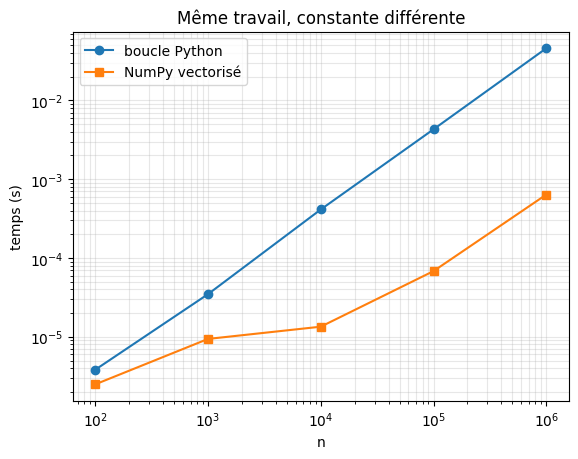

In [50]:
import numpy as np
import matplotlib.pyplot as plt

def somme_carres_python(L):
    s = 0
    for v in L:
        s += v * v
    return s

tailles, t_py, t_np = [10**k for k in range(2, 7)], [], []
for n in tailles:
    L = list(range(n)); A = np.arange(n, dtype=np.int64)
    t_py.append(min(timeit.repeat(lambda: somme_carres_python(L), number=1, repeat=3)))
    t_np.append(min(timeit.repeat(lambda: int((A * A).sum()), number=1, repeat=3)))

plt.loglog(tailles, t_py, "o-", label="boucle Python")
plt.loglog(tailles, t_np, "s-", label="NumPy vectorisé")
plt.xlabel("n"); plt.ylabel("temps (s)"); plt.title("Même travail, constante différente")
plt.grid(True, which="both", alpha=0.3); plt.legend(); plt.show()

> 🧠 Les deux droites sont-elles **parallèles** ? Que signifie la distance verticale entre elles ?

---
# Partie C — Exercices avancés

In [51]:
def verifier(nom, obtenu, attendu):
    print(("✅" if obtenu == attendu else "❌"), nom, "| obtenu :", obtenu, "| attendu :", attendu)

### Exercice A — Git : votre première branche (dans votre vrai dépôt `aac-tp`)
1. Créez une branche `tp0-bis`.
2. Ajoutez-y ce notebook et faites **au moins 2 commits**.
3. Publiez la branche (`git push -u origin tp0-bis`) et ouvrez une **Pull Request** vers `main`.
4. Fusionnez-la sur GitHub, puis `git switch main && git pull` en local.
5. **Bonus** : provoquez volontairement un conflit sur `README.md` entre deux branches et résolvez-le dans VS Code.

### Exercice B — Mémoïsation à la main
Écrire un décorateur `memoiser(f)` qui stocke les résultats dans un **dictionnaire**, **sans** utiliser `lru_cache`.

In [52]:
def memoiser(f):
    # À COMPLÉTER (supprimer la ligne raise)
    raise NotImplementedError("memoiser n'est pas encore écrit")

try:
    @memoiser
    def fib_m(n):
        return n if n <= 1 else fib_m(n - 1) + fib_m(n - 2)
    verifier("fib_m(80)", fib_m(80), 23416728348467685)   # sans mémoïsation, ce calcul ne termine pas
except NotImplementedError as e:
    print("❌", e)

❌ memoiser n'est pas encore écrit


> ⚠️ Si votre `memoiser` ne mémorise rien, la cellule **ne termine pas** (≈ $10^{16}$ appels). Interrompez-la avec le bouton ■.

### Exercice C — Recherche dichotomique avec compteur
Écrire `dichotomie(T, x)` qui renvoie `(indice, comparaisons)` dans une liste **triée** (`-1` si absent). Comparez ensuite le nombre de comparaisons à $\lfloor \log_2 n \rfloor + 1$.

In [53]:
def dichotomie(T, x):
    # À COMPLÉTER
    return -1, 0

T = list(range(0, 2000, 2))      # 1000 nombres pairs triés
verifier("indice de 1234", dichotomie(T, 1234)[0], 617)
verifier("1235 absent", dichotomie(T, 1235)[0], -1)
print("comparaisons :", dichotomie(T, 1234)[1], "| borne :", math.floor(math.log2(len(T))) + 1)

❌ indice de 1234 | obtenu : -1 | attendu : 617
✅ 1235 absent | obtenu : -1 | attendu : -1
comparaisons : 0 | borne : 10


> ⚠️ Pour que le compteur soit comparable à $\lfloor \log_2 n \rfloor + 1$, comptez **une comparaison par tour de boucle**.

### Exercice D — Les k mots les plus fréquents
Écrire `top_k(texte, k)` qui renvoie la liste des `k` mots les plus fréquents, du plus au moins fréquent (utilisez `Counter`).

In [54]:
def top_k(texte, k):
    # À COMPLÉTER
    pass

verifier("top_k", top_k("a b a c b a d", 2), ["a", "b"])

❌ top_k | obtenu : None | attendu : ['a', 'b']


### Exercice E — Générateur de nombres premiers
Écrire un **générateur** `premiers()` qui produit les nombres premiers un par un, indéfiniment.

In [55]:
def premiers():
    # À COMPLÉTER
    yield from ()

verifier("10 premiers", list(islice(premiers(), 10)), [2, 3, 5, 7, 11, 13, 17, 19, 23, 29])

❌ 10 premiers | obtenu : [] | attendu : [2, 3, 5, 7, 11, 13, 17, 19, 23, 29]


### Exercice F — Défi : liste contre ensemble ⭐
Pour $n \in \{10^2, 10^3, 10^4, 10^5\}$, mesurez avec `timeit` le temps de `x in liste` et de `x in ensemble` (pire cas : `x` absent). Tracez les deux courbes sur un graphique **log-log** et décrivez la différence de **forme** (pas seulement de hauteur).

In [56]:
# À COMPLÉTER

> *Vos observations :* …

---
# 📚 Récapitulatif

| Thème | À retenir |
|---|---|
| **Branches** | `switch -c`, `merge`, `branch -d`, un TP = une branche |
| **Conflits** | marqueurs `<<<<<<<` / `>>>>>>>`, éditer → `add` → `commit` |
| **Pull Request** | `push -u`, PR sur GitHub, relecture, fusion, `pull` |
| **Annuler** | `restore`, `revert` (sûr), `stash`, jamais réécrire l'historique partagé |
| **Générateurs** | mémoire constante au lieu de proportionnelle à $n$ |
| **Décorateurs** | instrumenter (compter, chronométrer) sans modifier l'algorithme |
| **Mémoïsation** | `lru_cache` : mémoire contre temps → programmation dynamique |
| **Structures** | `deque`, `Counter`, `defaultdict`, `heapq`, `bisect` : choisir la bonne change la complexité |
| **Mesure** | `timeit`, `%timeit`, NumPy change la constante, pas la forme |

### Ressources
- Pro Git (livre gratuit, FR) : https://git-scm.com/book/fr/v2
- Apprendre les branches de façon interactive : https://learngitbranching.js.org/?locale=fr_FR
- Bibliothèque standard Python : https://docs.python.org/fr/3/library/
- NumPy pour débutants : https://numpy.org/doc/stable/user/absolute_beginners.html